# Internal stress from noisy traction

This notebook actively solves the complete author-existing 50 by50 observation frame. The data are finite-element simulated tractions with author-added5% relative noise, not real-cell measurements. The authors also supply exact central stress from the same simulation. The fresh Gaussian inverse is compared with that truth and an independently executed original BISM run.

The physical unknown is the full height-integrated symmetric tensor, units kPa micrometres. Traction in kPa equals its divergence. There are two measured force components but three physical stress components, so symmetry, free boundaries and a Gaussian prior resolve an underdetermined spatial inverse. The original paper's Bayesian family is used in its supplied fixed-lambda branch; this is not a run of the hierarchical parameter-estimation alternative.

In [1]:
from pathlib import Path
import os,sys,time,json,hashlib,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/"src").exists():root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
from src.preprocessing import load_data,coordinates
from src.solvers import reconstruct,posterior_diagnostics
from src.physics_model import force_balance,center_stress
from src.visualization import image,principal,export
spec=importlib.util.spec_from_file_location("stress_judge",root/"evaluation/judge.py")
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
with np.load("evaluation/ground_truth.npz",allow_pickle=False) as f:truth=f["reconstruction"][0].copy()
with np.load("notebooks/reference_outputs/upstream.npz",allow_pickle=False) as f:upstream=dict(f)
figure_dir=Path(r"D:\yan1\agent\AutoSkill\imaging-101-maintainer\research_batch4_20261021\astro_earth_mechanics\bism_figures")
plt.rcParams.update({"font.size":10,"axes.titlesize":11})
traction=load_data();start=time.perf_counter()
fresh,state=reconstruct(traction)
mean_seconds=time.perf_counter()-start
np.savez_compressed("output/reconstruction.npz",reconstruction=fresh[None])
report,exit_code=judge.evaluate("output/reconstruction.npz")
print("Fresh full observation reconstruction:",mean_seconds,"seconds",report)
assert exit_code==0
print("Source/local central max error",float(np.max(np.abs(fresh-upstream["reconstruction"][0]))))
print("Closed-form stationarity norm",float(np.linalg.norm(state["gradient"])))

Fresh full observation reconstruction: 0.0485465000019758 seconds {'status': 'pass', 'passed': True, 'metrics': {'xx_ncc': 0.9677131820553927, 'xx_nrmse': 0.03219874256209875, 'yy_ncc': 0.9892072481321321, 'yy_nrmse': 0.01911766209011334, 'xy_ncc': 0.9801887227753011, 'xy_nrmse': 0.03815161942714859}, 'thresholds': {'xx_ncc': {'comparison': '>=', 'boundary': 0.8709418638620124}, 'xx_nrmse': {'comparison': '<=', 'boundary': 0.035418616810291466}, 'xy_ncc': {'comparison': '>=', 'boundary': 0.8821698505015243}, 'xy_nrmse': {'comparison': '<=', 'boundary': 0.04196678136561255}, 'yy_ncc': {'comparison': '>=', 'boundary': 0.8902865233201596}, 'yy_nrmse': {'comparison': '<=', 'boundary': 0.02102942829789748}}, 'errors': []}
Source/local central max error 1.2066295962398499e-08
Closed-form stationarity norm 3.103117881237085e-13


## Local executable mathematics

Flatten the four staggered face blocks in the order xx,yy,xy,yx. Adjacent signed differences divided by the2micrometre spacing form the divergence matrix A. Let D compare the sums of adjacent shear faces, and E select boundary stresses. The prior precision is B=I+1000² DᵀD+1000² EᵀE. The scaled objective is l²||A sigma−T||²+lambda sigmaᵀB sigma, with l=2 and lambda=1e−6. The closed-form posterior mean solves (lambda B+l²AᵀA)sigma=l²AᵀT. General sparse LU evaluates this formula directly; no invented iterative convergence is displayed.

Normal stresses are averages of two adjacent faces; physical shear averages four shear faces. The original paper uses a reduced covariance symbol whose inverse corresponds to the script's B; here B always means precision. Increasing row index is positive Cartesian y and is plotted upward, consistent with the original MATLAB quiver and principal-stress figures. Its row-order comment describes array display rather than those actual coordinate plots. The outer free boundary is0..100micrometres, while observed centers are1..99.

Force-balance RMS kPa 0.0008297180173024984
Interpolated shear mismatch RMS 1.2237132039131092e-05
Free-boundary face RMS 0.0018016076596520636


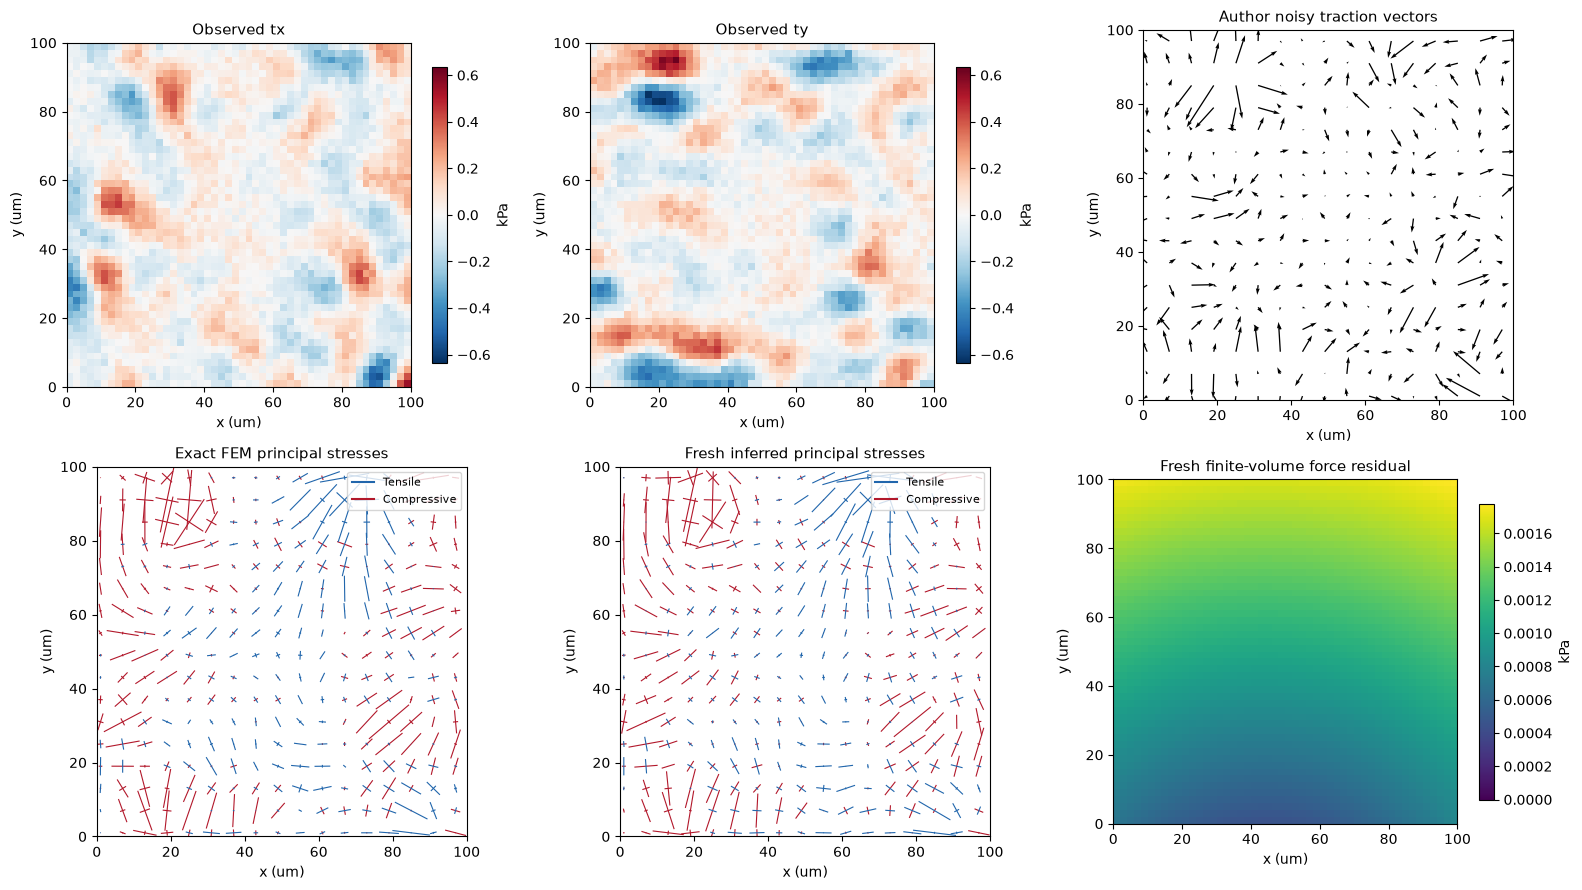

In [2]:
# Actual source-result parity and independent finite-volume conservation.
prediction=force_balance(state["vector"])
residual=prediction-traction
print("Force-balance RMS kPa",np.sqrt(np.mean(residual**2)))
print("Interpolated shear mismatch RMS",np.sqrt(np.mean((state["d"]@state["vector"]/2)**2)))
print("Free-boundary face RMS",np.sqrt(np.mean((state["e"]@state["vector"])**2)))
fig,axes=plt.subplots(2,3,figsize=(16,9))
scale=np.max(np.abs(traction))
image(axes[0,0],traction[0],"Observed tx","kPa",scale)
image(axes[0,1],traction[1],"Observed ty","kPa",scale)
x,y=coordinates();xx,yy=np.meshgrid(x,y)
axes[0,2].quiver(xx[::3,::3],yy[::3,::3],traction[0,::3,::3],traction[1,::3,::3],angles="xy",scale_units="xy",scale=.05)
axes[0,2].set(xlim=(0,100),ylim=(0,100),aspect="equal",title="Author noisy traction vectors",xlabel="x (um)",ylabel="y (um)")
principal(axes[1,0],truth,"Exact FEM principal stresses")
principal(axes[1,1],fresh,"Fresh inferred principal stresses")
image(axes[1,2],np.linalg.norm(residual,axis=0),"Fresh finite-volume force residual","kPa",cmap="viridis")
export(fig,figure_dir,"01_mechanics",traction=traction,prediction=prediction,residual=residual,truth=truth,fresh=fresh)
plt.show()

## Full tensor recovery

Each component is evaluated against the exact supplied finite-element stress without alignment or scale adjustment. The shared color limits in each row compare truth and reconstruction directly; the separate signed-error scale makes bias visible. The source-generated posterior mean is a distinct numerical comparison, not truth.

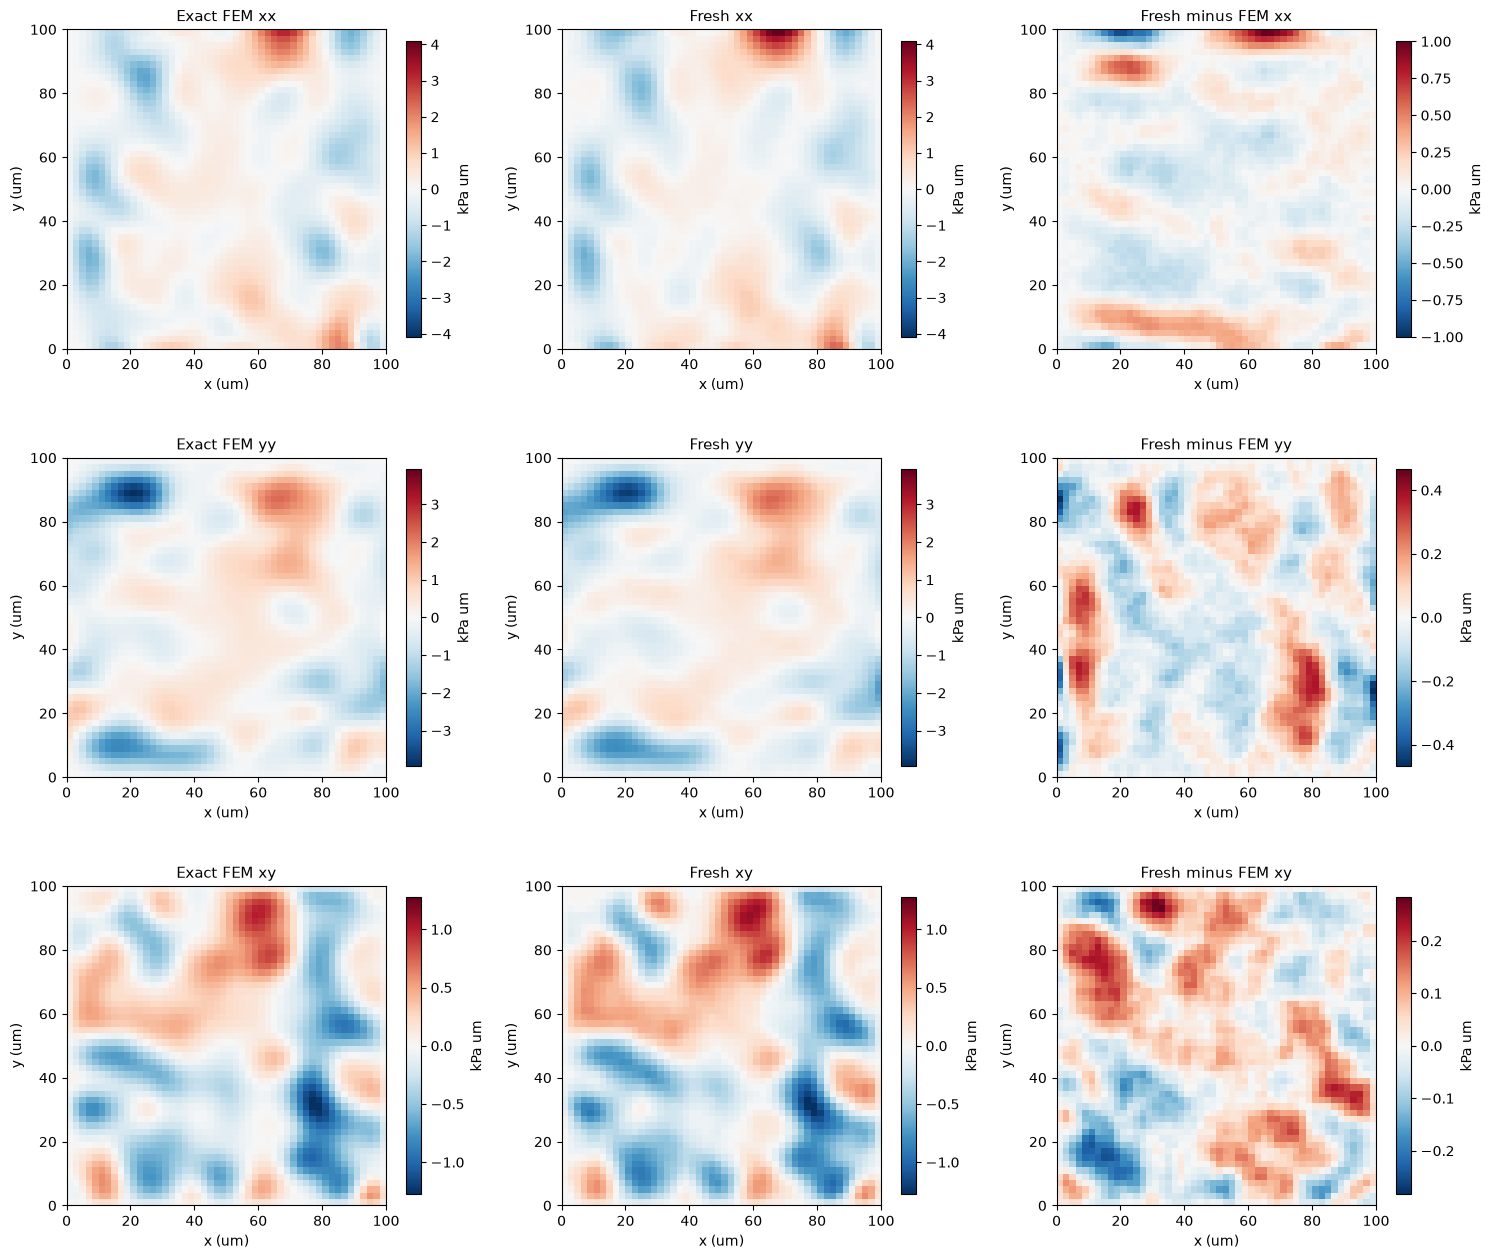

Original independently reproduced metrics {'xx_ncc': 0.9677131820689027, 'xx_nrmse': 0.03219874255481042, 'yy_ncc': 0.9892072481335106, 'yy_nrmse': 0.01911766208899771, 'xy_ncc': 0.9801887227794714, 'xy_nrmse': 0.038151619423284135}
Fresh metrics {'xx_ncc': 0.9677131820553927, 'xx_nrmse': 0.03219874256209875, 'yy_ncc': 0.9892072481321321, 'yy_nrmse': 0.01911766209011334, 'xy_ncc': 0.9801887227753011, 'xy_nrmse': 0.03815161942714859}


In [3]:
fig,axes=plt.subplots(3,3,figsize=(15,13))
for k,name in enumerate(["xx","yy","xy"]):
    limit=max(np.max(np.abs(truth[k])),np.max(np.abs(fresh[k])))
    image(axes[k,0],truth[k],"Exact FEM "+name,limit=limit)
    image(axes[k,1],fresh[k],"Fresh "+name,limit=limit)
    image(axes[k,2],fresh[k]-truth[k],"Fresh minus FEM "+name)
export(fig,figure_dir,"02_tensor",truth=truth,fresh=fresh,original=upstream["reconstruction"][0],error=fresh-truth,source_difference=fresh-upstream["reconstruction"][0])
plt.show()
print("Original independently reproduced metrics",judge.metrics(upstream["reconstruction"],truth[None]))
print("Fresh metrics",report["metrics"])

## Sensitivity and identifiability

These are fresh reconstructions of the same observations with one inverse assumption varied. The source default lambda is retained for the benchmark. Removing a boundary or symmetry constraint changes the inverse and can preserve force fit while altering stresses. This tests the meaning of agreement, rather than treating a small residual as proof of accurate stress.

The direct mean solve has one endpoint. The normal-equation residual and before/after objective are reported as numerical checks, not a fabricated iteration history. Lambda sweeps are different solved objectives, not convergence iterations.

Ablation metrics {'Standard': {'xx_ncc': 0.9677131820553927, 'xx_nrmse': 0.03219874256209875, 'yy_ncc': 0.9892072481321321, 'yy_nrmse': 0.01911766209011334, 'xy_ncc': 0.9801887227753011, 'xy_nrmse': 0.03815161942714859}, 'No boundary prior': {'xx_ncc': 0.7653912733960312, 'xx_nrmse': 0.07979649760222896, 'yy_ncc': 0.7329297318454114, 'yy_nrmse': 0.08902292638393017, 'xy_ncc': 0.7476143278153191, 'xy_nrmse': 0.11551291110180253}, 'No shear prior': {'xx_ncc': 0.9091417535922318, 'xx_nrmse': 0.05362953745717846, 'yy_ncc': 0.920735606272556, 'yy_nrmse': 0.05343547127306586, 'xy_ncc': 0.7958872360679992, 'xy_nrmse': 0.10335204376430299}}
Zero and direct-solution scaled objectives 373.6895488283396 0.018770509357908107


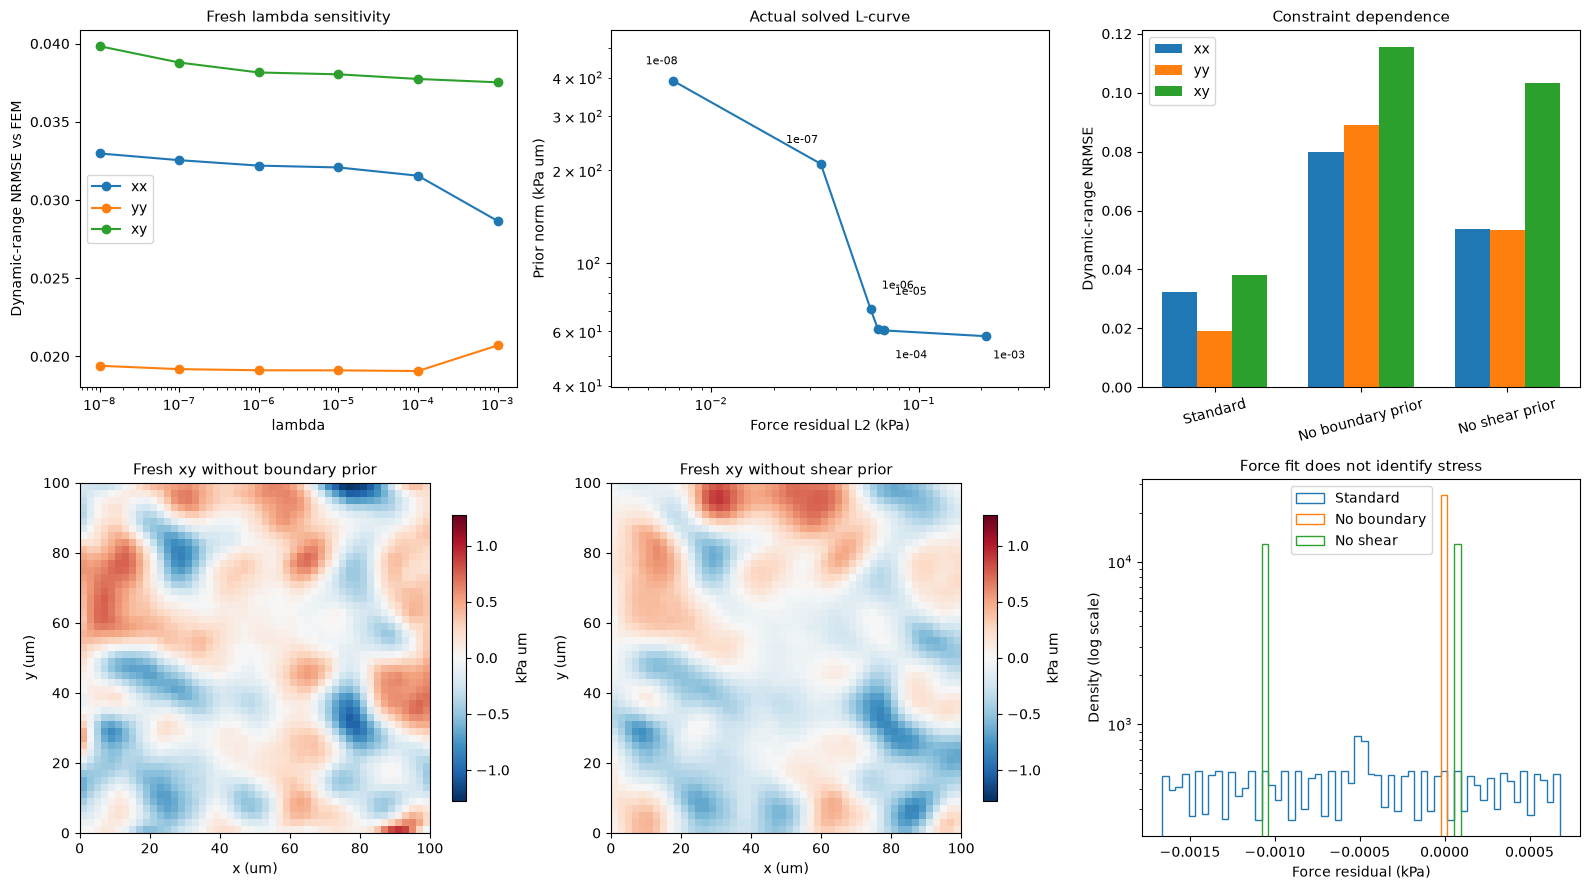

In [4]:
lambdas=np.logspace(-8,-3,6)
sensitivity=[];residual_norm=[];prior_norm=[];sensitivity_metrics=[]
for lam in lambdas:
    value,detail=reconstruct(traction,lam=float(lam))
    sensitivity.append(value)
    residual_norm.append(np.linalg.norm(detail["prediction"]-traction))
    prior_norm.append(np.sqrt(detail["vector"]@(detail["b"]@detail["vector"])))
    sensitivity_metrics.append(judge.metrics(value[None],truth[None]))
no_boundary,nb_state=reconstruct(traction,alpha_boundary=0.)
no_symmetry,ns_state=reconstruct(traction,alpha_shear=0.)
comparison=[fresh,no_boundary,no_symmetry];names=["Standard","No boundary prior","No shear prior"]
comparison_metrics=[judge.metrics(v[None],truth[None]) for v in comparison]
print("Ablation metrics",dict(zip(names,comparison_metrics)))
print("Zero and direct-solution scaled objectives",state["initial_objective"],state["objective"])
fig,axes=plt.subplots(2,3,figsize=(16,9))
for k,name in enumerate(["xx","yy","xy"]):
    axes[0,0].semilogx(lambdas,[m[name+"_nrmse"] for m in sensitivity_metrics],"o-",label=name)
axes[0,0].set(title="Fresh lambda sensitivity",xlabel="lambda",ylabel="Dynamic-range NRMSE vs FEM");axes[0,0].legend()
axes[0,1].loglog(residual_norm,prior_norm,"o-")
for x0,y0,lam,offset in zip(residual_norm,prior_norm,lambdas,[(-20,12),(-25,15),(8,15),(12,25),(8,-20),(5,-16)]):axes[0,1].annotate(f"{lam:.0e}",(x0,y0),xytext=offset,textcoords="offset points",fontsize=8)
axes[0,1].margins(.2);axes[0,1].set(title="Actual solved L-curve",xlabel="Force residual L2 (kPa)",ylabel="Prior norm (kPa um)")
for k,name in enumerate(["xx","yy","xy"]):
    axes[0,2].bar(np.arange(3)+k*.24,[m[name+"_nrmse"] for m in comparison_metrics],width=.24,label=name)
axes[0,2].set_xticks(np.arange(3)+.24,names,rotation=15);axes[0,2].set(title="Constraint dependence",ylabel="Dynamic-range NRMSE");axes[0,2].legend()
limit=max(np.max(np.abs(no_boundary[2])),np.max(np.abs(no_symmetry[2])),np.max(np.abs(fresh[2])))
image(axes[1,0],no_boundary[2],"Fresh xy without boundary prior",limit=limit)
image(axes[1,1],no_symmetry[2],"Fresh xy without shear prior",limit=limit)
all_residuals=[residual,nb_state["prediction"]-traction,ns_state["prediction"]-traction]
bins=np.linspace(min(v.min() for v in all_residuals),max(v.max() for v in all_residuals),61)
for value,label in zip(all_residuals,["Standard","No boundary","No shear"]):
    axes[1,2].hist(value.ravel(),bins=bins,density=True,histtype="step",label=label)
axes[1,2].set(title="Force fit does not identify stress",xlabel="Force residual (kPa)",ylabel="Density (log scale)",yscale="log");axes[1,2].legend()
export(fig,figure_dir,"03_sensitivity",lambdas=lambdas,stress=np.array(sensitivity),residual_norm=residual_norm,prior_norm=prior_norm,standard=fresh,no_boundary=no_boundary,no_symmetry=no_symmetry,standard_residual=residual,no_boundary_residual=nb_state["prediction"]-traction,no_symmetry_residual=ns_state["prediction"]-traction,metrics=np.array([[m[c+"_nrmse"] for c in ["xx","yy","xy"]] for m in sensitivity_metrics]))
plt.show()

## Covariance propagation and original error-bar approximation

The script's noise_value=.001kPa is its chosen conditional uncertainty scale. It is not the true5% simulation noise standard deviation and is not an observational calibration claim. With H=lambda B+l²AᵀA, the complete face covariance is C=.001²l²H⁻¹. For interpolation L, proper central covariance is LCLᵀ. Its diagonal includes neighboring-face and cross-shear covariance.

The original plotted errors instead retain only squared interpolation weights times diag(C), omitting all cross terms. We preserve that result under its explicit approximate label and compute correct propagation as an additional diagnosis, without changing the published mean. Scatter bars show one conditional standard deviation at a fixed sparse subset for legibility. Their size is not calibrated coverage of FEM discretization or actual5% noise error.

Fresh full native uncertainty diagnostic seconds 16.965529099998093
Original conditional covariance sample max difference 4.221900606893314e-12
Exact variance original/local max difference 6.275064912131256e-10
Original diagonal-only error local max difference 2.018428757466495e-10


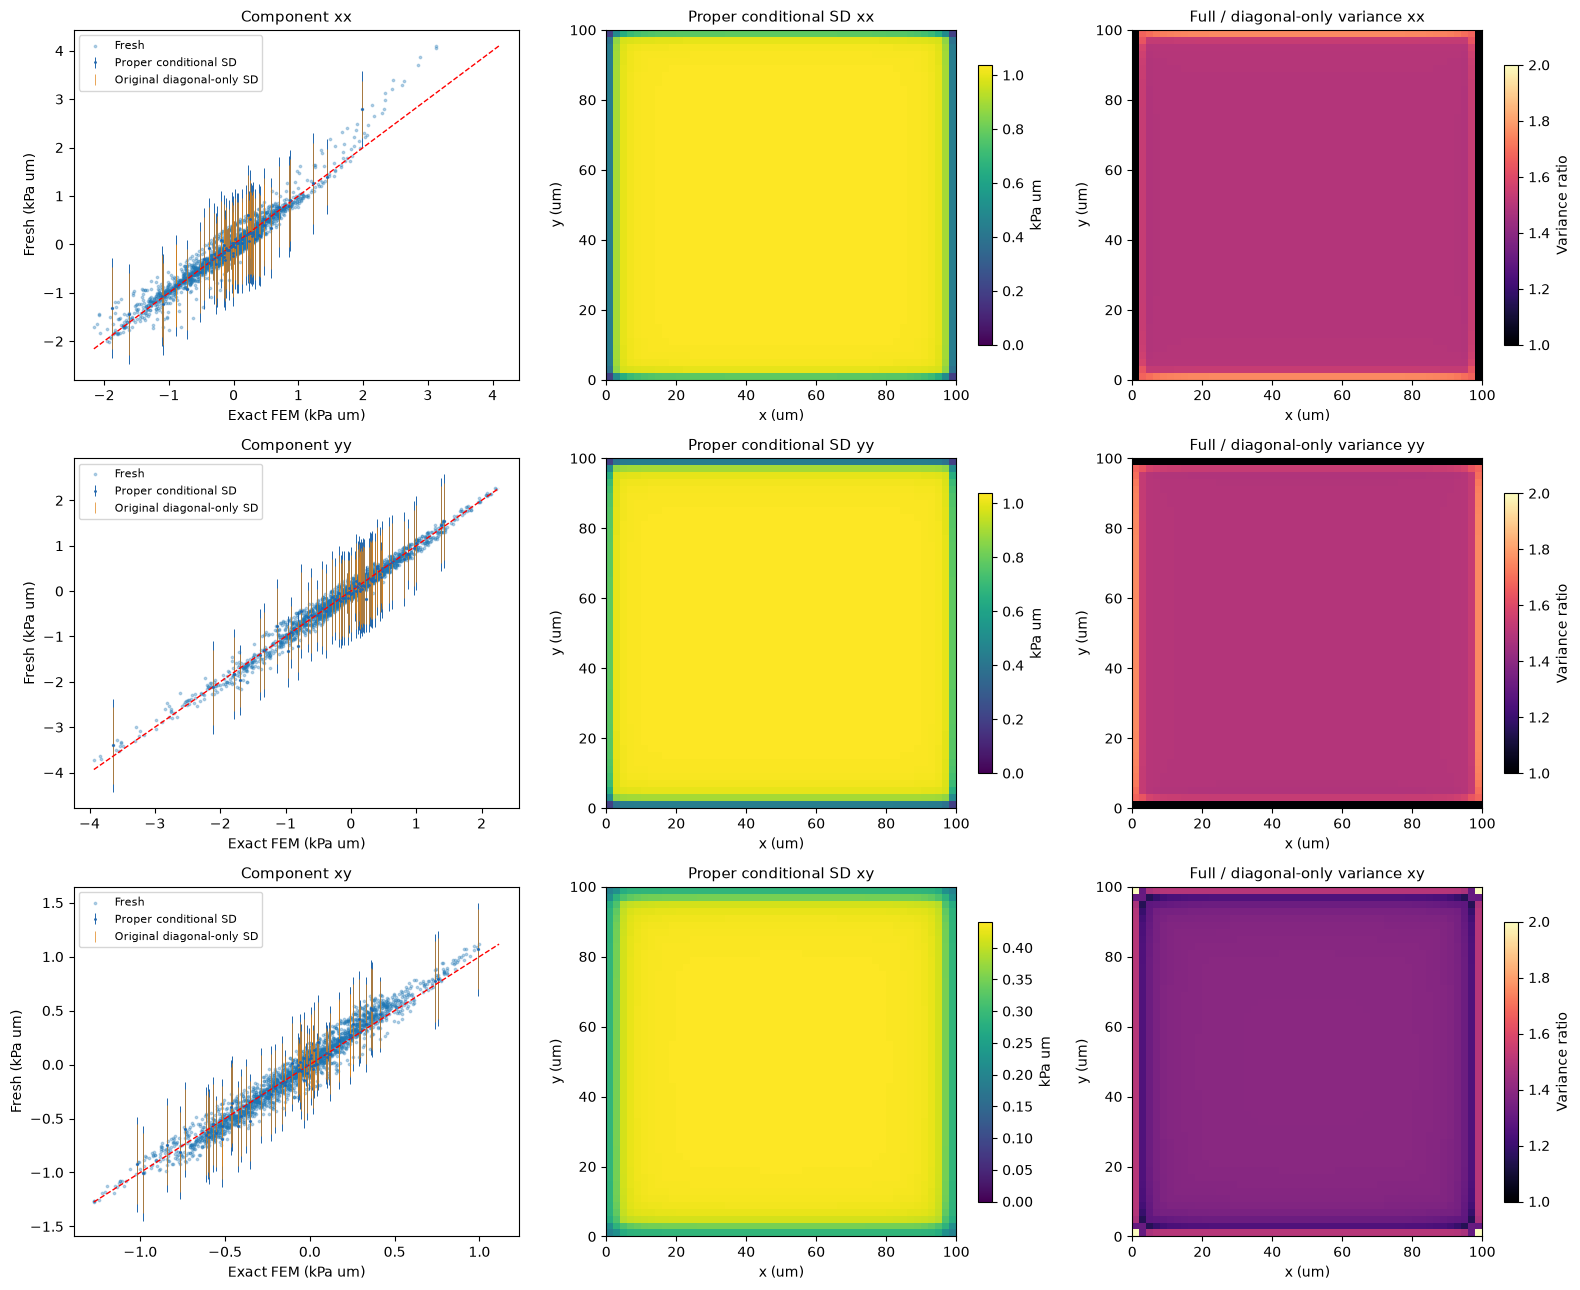

2683

In [5]:
start=time.perf_counter()
indices=np.array([0,1,50,51,2549,2550,2600,5099,5100,5101,5150,7649,7650,7651,7700,10199])
uncertainty=posterior_diagnostics(state,indices=indices,batch_size=32)
uncertainty_seconds=time.perf_counter()-start
exact=uncertainty["exact_variance"];approx=uncertainty["diagonal_only_variance"]
print("Fresh full native uncertainty diagnostic seconds",uncertainty_seconds)
print("Original conditional covariance sample max difference",np.max(np.abs(uncertainty["covariance_samples"]-upstream["covariance_samples"])))
print("Exact variance original/local max difference",np.max(np.abs(exact-upstream["proper_center_variance"])))
print("Original diagonal-only error local max difference",np.max(np.abs(np.sqrt(approx)-upstream["diagonal_only_error"])))
fig,axes=plt.subplots(3,3,figsize=(16,13))
for k,name in enumerate(["xx","yy","xy"]):
    target=truth[k].ravel();estimate=fresh[k].ravel()
    axes[k,0].scatter(target,estimate,s=3,alpha=.3,label="Fresh")
    subset=np.arange(0,2500,40)
    axes[k,0].errorbar(target[subset],estimate[subset],yerr=np.sqrt(exact[k].ravel()[subset]),fmt=".",markersize=2,linewidth=.7,color="#2166ac",label="Proper conditional SD")
    axes[k,0].errorbar(target[subset],estimate[subset],yerr=upstream["diagonal_only_error"][k].ravel()[subset],fmt="none",linewidth=.5,color="#e08214",label="Original diagonal-only SD")
    low=min(target.min(),estimate.min());high=max(target.max(),estimate.max());axes[k,0].plot([low,high],[low,high],"r--",linewidth=1)
    axes[k,0].set(title="Component "+name,xlabel="Exact FEM (kPa um)",ylabel="Fresh (kPa um)");axes[k,0].legend(fontsize=8)
    image(axes[k,1],np.sqrt(exact[k]),"Proper conditional SD "+name,"kPa um",cmap="viridis")
    ratio=exact[k]/approx[k]
    artist=axes[k,2].imshow(ratio,extent=[0,100,0,100],origin="lower",vmin=1,vmax=2,cmap="magma")
    axes[k,2].set(title="Full / diagonal-only variance "+name,xlabel="x (um)",ylabel="y (um)")
    plt.colorbar(artist,ax=axes[k,2],shrink=.8,label="Variance ratio")
export(fig,figure_dir,"04_covariance",truth=truth,fresh=fresh,proper_variance=exact,original_diagonal_only_variance=upstream["diagonal_only_error"]**2,fresh_diagonal_only_variance=approx,covariance_indices=indices,covariance_samples=uncertainty["covariance_samples"])
plt.show()
np.savez_compressed("notebooks/reference_outputs/fresh.npz",reconstruction=fresh[None],prediction=prediction,residual=residual,face_vector=state["vector"],proper_variance=exact,diagonal_only_variance=approx,lambda_values=lambdas,sensitivity_stress=np.array(sensitivity),no_boundary=no_boundary,no_symmetry=no_symmetry)
manifest=[]
for f in sorted(figure_dir.glob("*")):
    if f.suffix in [".png",".svg",".pdf",".npz"]:manifest.append(dict(file=f.name,bytes=f.stat().st_size,sha256=hashlib.sha256(f.read_bytes()).hexdigest()))
(figure_dir/"manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
(figure_dir/"experiment_summary.json").write_text(json.dumps(dict(mean_seconds=mean_seconds,uncertainty_seconds=uncertainty_seconds,metrics=report["metrics"],lambda_metrics=sensitivity_metrics,ablation_metrics=comparison_metrics,force_rms_kpa=float(np.sqrt(np.mean(residual**2))),normal_equation_gradient_norm=float(np.linalg.norm(state["gradient"])),variance_ratio_range=[float(np.min(exact/approx)),float(np.max(exact/approx))]),indent=2),encoding="utf-8")

## Interpretation

All three stress components pass independent truth-based evaluation, with no hidden scaling or alignment. Reproducing the original staggered inverse is supported separately by exact operator fixtures, full mean-field parity, finite-volume conservation, finite-difference gradients and covariance tests. The stress-prior ablations show why excellent force fit alone does not establish a unique internal stress.

The exact FEM tensor provides simulation truth, but the original FEM mesh and precise noise realization are unavailable. Central-difference divergence of that sampled truth does not exactly reproduce noisy input tractions. The chosen uncertainty model also understates the source-added noise and omits numerical-model discrepancy; the corrected propagation diagnoses interpolation alone. These limits prevent interpreting conditional error bars as calibrated physical accuracy.